<a href="https://colab.research.google.com/github/elisabethandriivna/Portfolio/blob/main/Lab4_Kaprelova.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

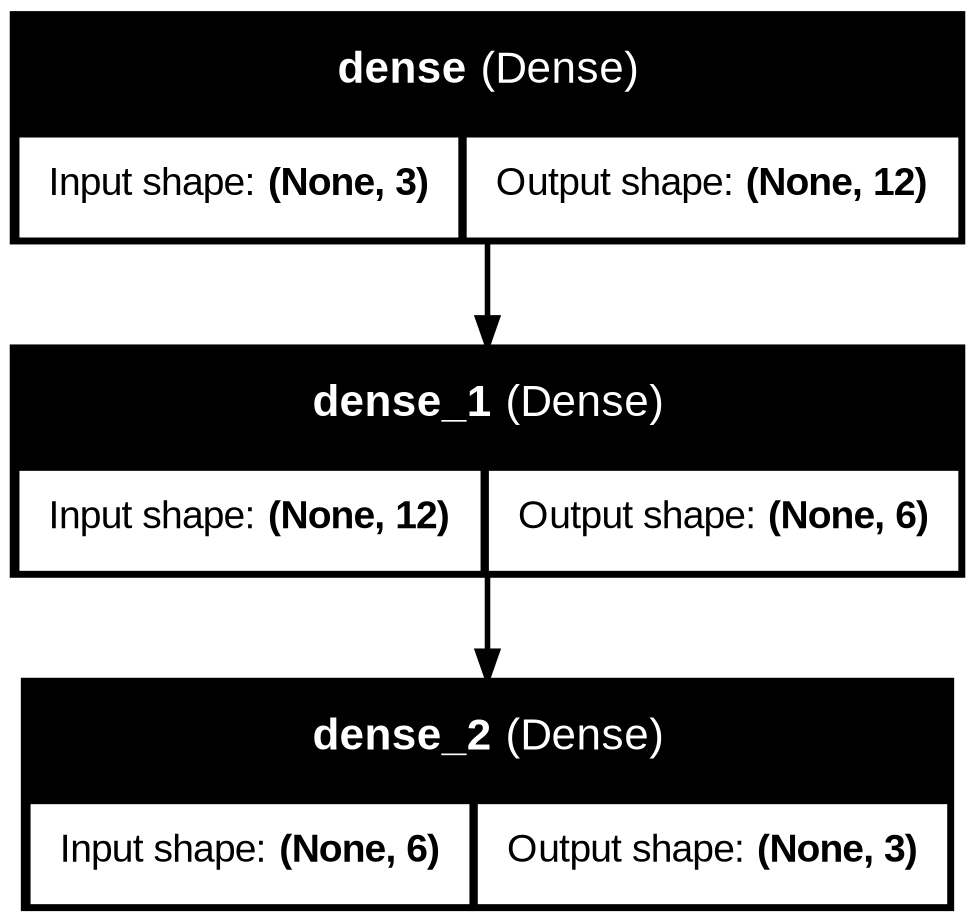

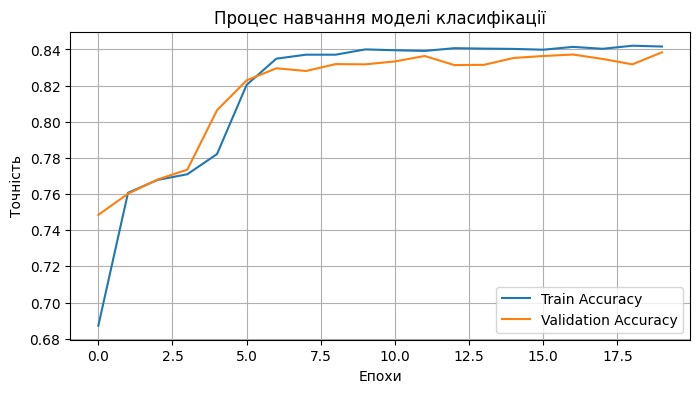

288/288 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

=== Результати класифікації ===
              precision    recall  f1-score   support

      Дешеві       0.87      0.92      0.89      3047
      Дорогі       0.88      0.88      0.88      3128
     Середні       0.79      0.75      0.77      3030

    accuracy                           0.85      9205
   macro avg       0.85      0.85      0.85      9205
weighted avg       0.85      0.85      0.85      9205

Загальна точність: 0.848


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


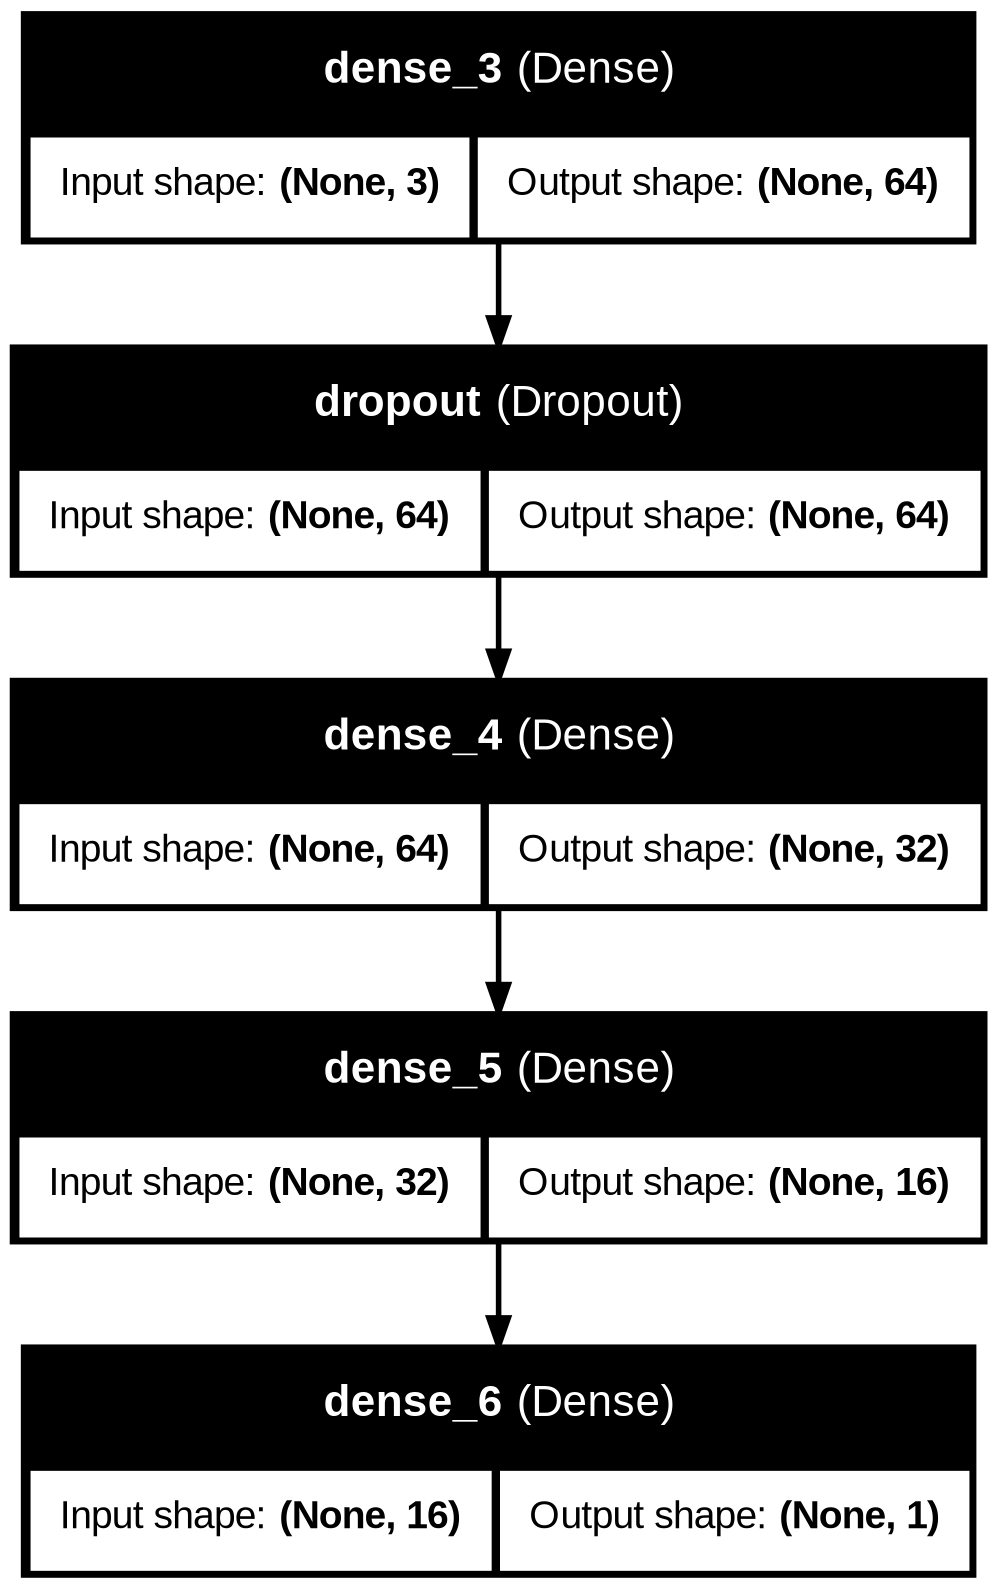

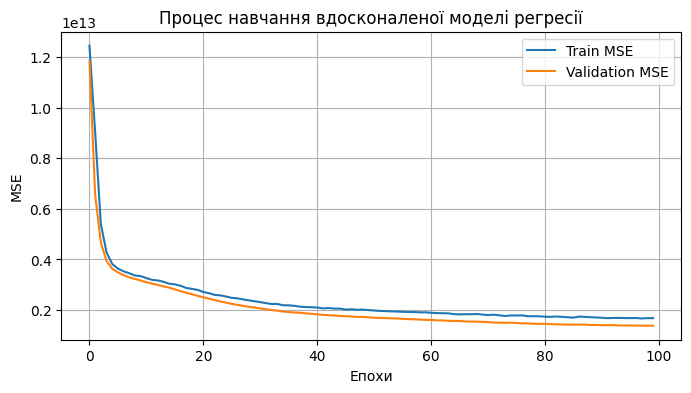

288/288 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

=== Результати регресії ===
Середньоквадратична помилка (MSE): 1725148168192.0
Коефіцієнт детермінації (R²): 0.806


In [1]:
# -*- coding: utf-8 -*-
"""Lab4.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1_KhaKzApQXB4dL8hvivTzzbDtqL2bEUw
"""

# --- 1) Встановлення бібліотек ---
!pip install -q tensorflow keras matplotlib scikit-learn pydot

# --- 2) Імпорт бібліотек ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, accuracy_score, mean_squared_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.utils import plot_model
from IPython.display import Image, display

# --- 3) Завантаження даних ---
DATA_PATH = 'Clean Data_pakwheels.csv'
df = pd.read_csv(DATA_PATH)

# --- 4) Підготовка даних ---
price_col = [c for c in df.columns if 'price' in c.lower()][0]
df['price_class'] = pd.qcut(df[price_col], q=3, labels=['Дешеві', 'Середні', 'Дорогі'])

features = ['Model Year', 'Mileage', 'Engine Capacity']
for f in features + [price_col]:
    if df[f].isnull().any():
        df[f].fillna(df[f].median(), inplace=True)

X = df[features]
y_class = df['price_class']
y_reg = df[price_col]

# Стандартизація ознак
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Кодування класів
le = LabelEncoder()
y_class_enc = le.fit_transform(y_class)

# Поділ на train/test
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_scaled, y_class_enc, test_size=0.2, random_state=42)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_scaled, y_reg, test_size=0.2, random_state=42)



# --- 5) МОДЕЛЬ КЛАСИФІКАЦІЇ ---
model_class = Sequential([
    Input(shape=(X_train_c.shape[1],)),
    Dense(12, activation='relu'),
    Dense(6, activation='relu'),
    Dense(3, activation='softmax')
])

model_class.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history_c = model_class.fit(X_train_c, y_train_c, epochs=20, batch_size=32, validation_split=0.2, verbose=0)

# --- Візуалізація архітектури класифікаційної моделі ---
plot_model(model_class, to_file='model_classification.png', show_shapes=True, show_layer_names=True)
display(Image(filename='model_classification.png'))

# --- Візуалізація процесу навчання ---
plt.figure(figsize=(8,4))
plt.plot(history_c.history['accuracy'], label='Train Accuracy')
plt.plot(history_c.history['val_accuracy'], label='Validation Accuracy')
plt.title('Процес навчання моделі класифікації')
plt.xlabel('Епохи')
plt.ylabel('Точність')
plt.legend()
plt.grid(True)
plt.show()

# --- Оцінка якості класифікації ---
y_pred_c = np.argmax(model_class.predict(X_test_c), axis=1)
print("\n=== Результати класифікації ===")
print(classification_report(y_test_c, y_pred_c, target_names=le.classes_))
print("Загальна точність:", round(accuracy_score(y_test_c, y_pred_c), 3))



# --- 6) МОДЕЛЬ РЕГРЕСІЇ ---
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from IPython.display import Image, display
from tensorflow.keras.utils import plot_model
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score

# --- Створення вдосконаленої моделі ---
model = Sequential([
    Dense(64, input_dim=3, activation='relu'),
    Dropout(0.1),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

# --- Навчання ---
history_r = model.fit(X_train_r, y_train_r, epochs=100, batch_size=32, validation_split=0.2, verbose=0)

# --- Візуалізація архітектури ---
plot_model(model, to_file='model_regression.png', show_shapes=True, show_layer_names=True)
display(Image(filename='model_regression.png'))

# --- Графік навчання ---
plt.figure(figsize=(8,4))
plt.plot(history_r.history['loss'], label='Train MSE')
plt.plot(history_r.history['val_loss'], label='Validation MSE')
plt.title('Процес навчання вдосконаленої моделі регресії')
plt.xlabel('Епохи')
plt.ylabel('MSE')
plt.legend()
plt.grid(True)
plt.show()

# --- Оцінка якості ---
y_pred_r = model.predict(X_test_r).flatten()
print("\n=== Результати регресії ===")
print("Середньоквадратична помилка (MSE):", round(mean_squared_error(y_test_r, y_pred_r), 2))
print("Коефіцієнт детермінації (R²):", round(r2_score(y_test_r, y_pred_r), 3))